# 02 · Prototipo 1D: un frente de fuego que avanza

Resolvemos la versión 1D del modelo adimensional (ver `docs/modelo.md` y el notebook 01):

$$u_\tau = u_{\xi\xi} - w\,u_\xi + a\,\beta\, r(u) - u, \qquad \beta_\tau = -e\,\beta\, r(u), \qquad r(u) = e^{-b/u}\ (u>0)$$

El objetivo es ver que existe un frente viajero, medir su velocidad $c$ y estudiar de qué depende. Esto sirve de prueba de concepto del solver 2D y de **referencia teórica** para validarlo después.

## Esquema numérico

- Malla uniforme $\xi_i = (i + \tfrac12)\Delta\xi$; Neumann ($u_\xi = 0$) en los bordes, con celdas fantasma.
- Difusión con diferencias centradas: $u_{\xi\xi} \approx (u_{i+1} - 2u_i + u_{i-1})/\Delta\xi^2$.
- Viento con **upwind** de primer orden: se usa la diferencia hacia atrás si $w > 0$ y hacia adelante si $w < 0$.
- Euler explícito en el tiempo, con $\Delta\tau$ acotado por tres condiciones:
  - difusión: $\Delta\tau \le \Delta\xi^2/2$;
  - advección (CFL): $\Delta\tau \le \Delta\xi/|w|$;
  - reacción: $\Delta\tau\,\max|\partial_u R| < 1$.

  Se multiplica el mínimo de las tres por un factor de seguridad de 0.4.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd().parent))
from app.contracts import BURNING_T_U8, BURNT_BETA_U8, T_U8_MAX, T_U8_MIN
from app.solver.model import (
    Dimensionless, PhysicalParams, length_scale, reaction_rate_u, speed_scale,
    time_scale, to_dimensionless, u_to_T, T_to_u,
)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
p = PhysicalParams()
d = to_dimensionless(p)
L, t0, v0 = length_scale(p), time_scale(p), speed_scale(p)
T_BURNING = T_U8_MIN + BURNING_T_U8 / 255 * (T_U8_MAX - T_U8_MIN)
u_burn = float(T_to_u(T_BURNING, p))
BETA_BURNT = BURNT_BETA_U8 / 255
print(d, f"| L = {L:.3f} m, 1/C = {t0:g} s, √(κC) = {v0:.4f} m/s")

Dimensionless(a=50.0, b=2.3, e=8.0) | L = 2.236 m, 1/C = 10 s, √(κC) = 0.2236 m/s


In [2]:
SAFETY = 0.4


def stable_dt(d: Dimensionless, dx: float, w: float, beta0: float) -> float:
    # max of d/du [a β e^{-b/u}] is at u = b/2: a β e^{-2} 4/b
    r_max = d.a * beta0 * np.exp(-2.0) * 4.0 / d.b
    limits = [dx * dx / 2.0, 1.0 / (r_max + 1.0)]
    if w != 0:
        limits.append(dx / abs(w))
    return SAFETY * min(limits)


def solve_1d(d, dx, length=80.0, tau_end=20.0, w=0.0, beta0=1.0,
             ign_len=3.0, ign_u=3.0, n_snaps=8):
    n = int(round(length / dx))
    x = (np.arange(n) + 0.5) * dx
    u = np.where(x < ign_len, ign_u, 0.0)
    beta = np.full(n, float(beta0))
    dt = stable_dt(d, dx, w, beta0)
    n_steps = int(np.ceil(tau_end / dt))
    snap_at = set(np.linspace(0, n_steps, n_snaps).astype(int))
    rec_every = max(1, int(0.05 / dt))
    snaps, front_t, front_x, umax = [], [], [], np.zeros(n)
    for k in range(n_steps + 1):
        if k in snap_at:
            snaps.append((k * dt, u.copy(), beta.copy()))
        if k % rec_every == 0:
            hot = np.flatnonzero(u > u_burn)
            front_t.append(k * dt)
            front_x.append(x[hot[-1]] if hot.size else np.nan)
        if k == n_steps:
            break
        g = np.concatenate(([u[0]], u, [u[-1]]))  # Neumann ghost cells
        lap = (g[2:] - 2 * u + g[:-2]) / dx**2
        if w > 0:
            adv = w * (u - g[:-2]) / dx
        elif w < 0:
            adv = w * (g[2:] - u) / dx
        else:
            adv = 0.0
        r = reaction_rate_u(u, d.b)
        u, beta = u + dt * (lap - adv + d.a * beta * r - u), beta - dt * d.e * beta * r
        umax = np.maximum(umax, u)
        if not np.all(np.isfinite(u)):
            raise FloatingPointError("NaN in u")
    return dict(x=x, dx=dx, dt=dt, snaps=snaps, front_t=np.array(front_t),
                front_x=np.array(front_x), umax=umax, beta=beta, length=length)


def front_speed(sol, t_min=3.0, edge=0.85):
    t, xf = sol["front_t"], sol["front_x"]
    ok = (t >= t_min) & np.isfinite(xf) & (xf < edge * sol["length"])
    if ok.sum() < 5 or np.isnan(xf[-1]):
        return 0.0  # front died or never formed
    return float(np.polyfit(t[ok], xf[ok], 1)[0])


t_start = time.perf_counter()
base = solve_1d(d, dx=0.2)
c_base = front_speed(base)
print(f"dt = {base['dt']:.4f}, celdas = {base['x'].size}, tiempo de cómputo = {time.perf_counter() - t_start:.2f} s")
print(f"c* = {c_base:.3f}  ->  c = c*·√(κC) = {c_base * v0:.3f} m/s")

dt = 0.0080, celdas = 400, tiempo de cómputo = 0.02 s
c* = 2.888  ->  c = c*·√(κC) = 0.646 m/s


## Perfiles del frente

Se grafica en unidades físicas: $x = L\xi$ (m), $T = T_\infty(1+u)$ (K).

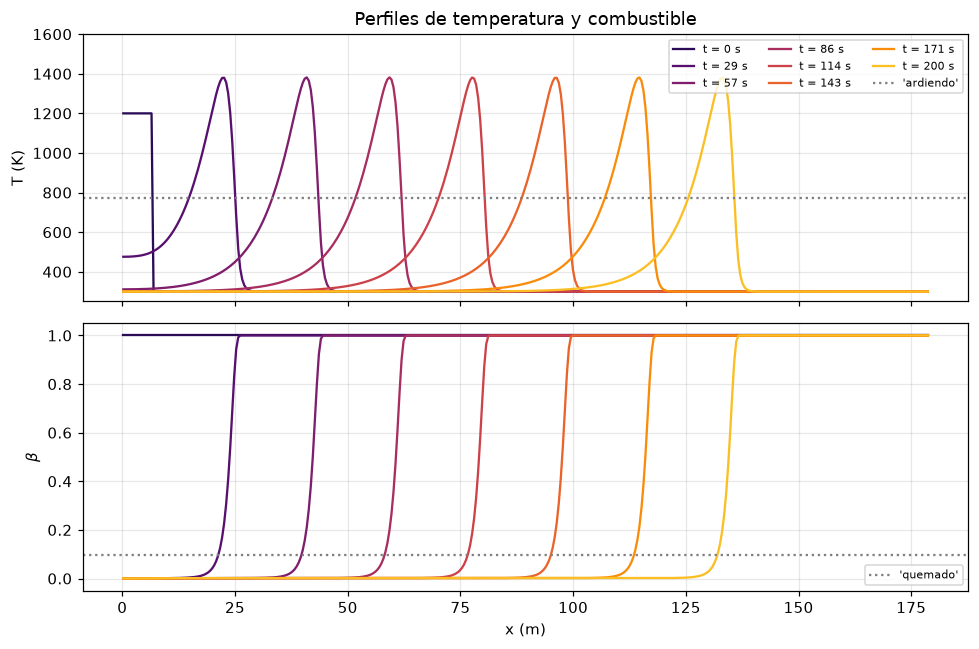

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
cmap = plt.cm.inferno
for i, (tau, u, beta) in enumerate(base["snaps"]):
    c = cmap(0.15 + 0.7 * i / max(1, len(base["snaps"]) - 1))
    ax[0].plot(base["x"] * L, u_to_T(u, p), color=c, label=f"t = {tau * t0:.0f} s")
    ax[1].plot(base["x"] * L, beta, color=c)
ax[0].axhline(T_BURNING, color="gray", ls=":", label="'ardiendo'")
ax[0].set(ylabel="T (K)", ylim=(250, T_U8_MAX + 100), title="Perfiles de temperatura y combustible")
ax[0].legend(ncol=3, fontsize=7)
ax[1].axhline(BETA_BURNT, color="gray", ls=":", label="'quemado'")
ax[1].set(xlabel="x (m)", ylabel=r"$\beta$")
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

Después de un transitorio inicial, el perfil de temperatura viaja **sin cambiar de forma**: es una onda viajera. Delante del frente el combustible está intacto; detrás queda casi agotado y la temperatura vuelve a la ambiente.

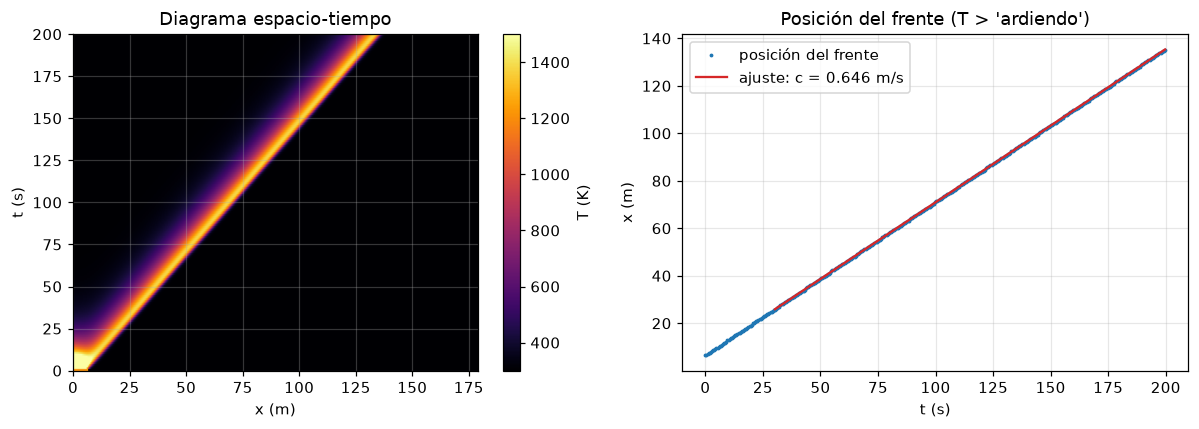

In [4]:
fine = solve_1d(d, dx=0.2, n_snaps=200)
T_map = np.array([u_to_T(u, p) for _, u, _ in fine["snaps"]])
taus = np.array([tau for tau, _, _ in fine["snaps"]])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(T_map, origin="lower", aspect="auto", cmap="inferno",
                  extent=[0, fine["length"] * L, 0, taus[-1] * t0], vmin=T_U8_MIN, vmax=T_U8_MAX)
fig.colorbar(im, ax=ax[0], label="T (K)")
ax[0].set(xlabel="x (m)", ylabel="t (s)", title="Diagrama espacio-tiempo")

t, xf = fine["front_t"], fine["front_x"]
ok = (t >= 3) & (xf < 0.85 * fine["length"])
coef = np.polyfit(t[ok], xf[ok], 1)
ax[1].plot(t * t0, xf * L, ".", ms=3, label="posición del frente")
ax[1].plot(t[ok] * t0, np.polyval(coef, t[ok]) * L, "C3", label=f"ajuste: c = {coef[0] * v0:.3f} m/s")
ax[1].set(xlabel="t (s)", ylabel="x (m)", title="Posición del frente (T > 'ardiendo')")
ax[1].legend()
plt.tight_layout()
plt.show()

En el diagrama espacio-tiempo, la franja caliente es una recta, así que la velocidad es constante. El ajuste lineal (descartando el transitorio $\tau < 3$) da la velocidad del frente.

### Ancho del frente, pico y combustible residual

El ancho del frente indica qué tan fina debe ser la malla 2D: se necesitan varias celdas dentro del frente para resolverlo.

In [5]:
tau_last, u_last, beta_last = base["snaps"][-2]
T_last = u_to_T(u_last, p)
hot = np.flatnonzero(u_last > 0.1 * u_last.max())
width_m = (base["x"][hot[-1]] - base["x"][hot[0]]) * L
mid = (base["x"] > 0.3 * base["length"]) & (base["x"] < 0.5 * base["length"])
peak_K = float(u_to_T(base["umax"][mid].mean(), p))
residual = float(base["beta"][mid].mean())

rows = [
    ("Velocidad c* (adimensional)", f"{c_base:.3f}"),
    ("Velocidad c (m/s)", f"{c_base * v0:.3f}"),
    ("Pico de T dentro del frente (K)", f"{peak_K:.0f}"),
    ("Combustible residual β", f"{residual:.3f}"),
    ("Zona caliente (u > 10 % del pico) (m)", f"{width_m:.1f}"),
    ("Celdas de 1 m dentro de la zona caliente", f"{width_m:.0f}"),
]
display(Markdown("| Cantidad | Valor |\n|---|---|\n" + "\n".join(f"| {k} | {v} |" for k, v in rows)))

| Cantidad | Valor |
|---|---|
| Velocidad c* (adimensional) | 2.888 |
| Velocidad c (m/s) | 0.646 |
| Pico de T dentro del frente (K) | 1382 |
| Combustible residual β | 0.002 |
| Zona caliente (u > 10 % del pico) (m) | 21.5 |
| Celdas de 1 m dentro de la zona caliente | 21 |

## Sensibilidad a la malla

Repetimos con varios $\Delta\xi$. El valor $\Delta\xi = 1\,\text{m}/L$ corresponde a las celdas de 1 m de las escenas actuales. Si $c$ converge al refinar, el esquema es consistente y podemos estimar el error de usar la malla de la escena. La prueba de convergencia formal en 2D va en el Bloque D.

| Δξ | Δx (m) | Δτ | c* | error relativo vs. Δξ = 0.05 | cómputo (s) |
|---|---|---|---|---|---|
| 0.447 | 1.00 | 3.13e-02 | 2.6967 | 8.17% | 0.01 |
| 0.400 | 0.89 | 3.13e-02 | 2.7232 | 7.27% | 0.01 |
| 0.200 | 0.45 | 8.00e-03 | 2.8876 | 1.67% | 0.02 |
| 0.100 | 0.22 | 2.00e-03 | 2.9269 | 0.33% | 0.11 |
| 0.050 | 0.11 | 5.00e-04 | 2.9365 | 0.00% | 0.58 |

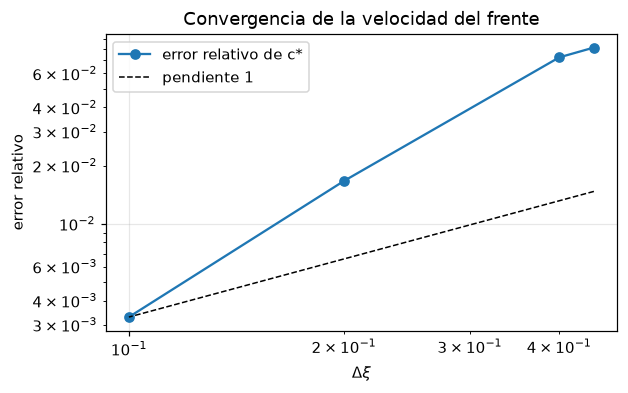

In [6]:
dxs = [1.0 / L, 0.4, 0.2, 0.1, 0.05]
conv = []
for dx in dxs:
    t_start = time.perf_counter()
    s = solve_1d(d, dx=dx)
    conv.append((dx, front_speed(s), s["dt"], time.perf_counter() - t_start))
c_ref = conv[-1][1]

lines = ["| Δξ | Δx (m) | Δτ | c* | error relativo vs. Δξ = 0.05 | cómputo (s) |", "|---|---|---|---|---|---|"]
for dx, c, dt, wall in conv:
    lines.append(f"| {dx:.3f} | {dx * L:.2f} | {dt:.2e} | {c:.4f} | {abs(c - c_ref) / c_ref:.2%} | {wall:.2f} |")
display(Markdown("\n".join(lines)))

fig, ax = plt.subplots(figsize=(6, 3.5))
errs = [abs(c - c_ref) / c_ref for _, c, _, _ in conv[:-1]]
ax.loglog(dxs[:-1], errs, "o-", label="error relativo de c*")
ax.loglog(dxs[:-1], errs[-1] * (np.array(dxs[:-1]) / dxs[-2]), "k--", lw=1, label="pendiente 1")
ax.set(xlabel=r"$\Delta\xi$", ylabel="error relativo", title="Convergencia de la velocidad del frente")
ax.legend()
plt.show()

## Velocidad según el combustible: umbral de propagación

Barremos el combustible inicial $\beta_0$, que es lo que el mapa de árboles controlará en 2D. Si el frente se apaga, se reporta $c = 0$.

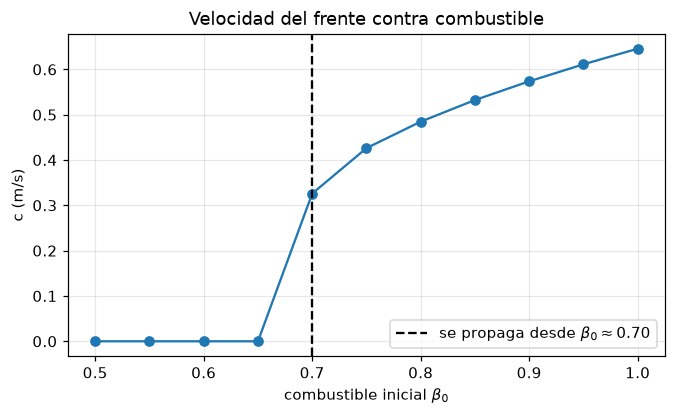

| β₀ | c (m/s) | pico T (K) |
|---|---|---|
| 0.50 | 0.000 | 300 |
| 0.55 | 0.000 | 300 |
| 0.60 | 0.000 | 300 |
| 0.65 | 0.000 | 300 |
| 0.70 | 0.326 | 798 |
| 0.75 | 0.426 | 950 |
| 0.80 | 0.485 | 1050 |
| 0.85 | 0.532 | 1139 |
| 0.90 | 0.574 | 1223 |
| 0.95 | 0.611 | 1303 |
| 1.00 | 0.646 | 1382 |

In [7]:
beta0s = np.round(np.arange(0.5, 1.001, 0.05), 3)
c_beta, peak_beta = [], []
for b0 in beta0s:
    s = solve_1d(d, dx=0.2, beta0=b0)
    c_beta.append(front_speed(s))
    x_end = s["front_x"][-1]
    m = (s["x"] > 0.25 * s["length"]) & (s["x"] < (0.8 * x_end if np.isfinite(x_end) else 0))
    peak_beta.append(float(u_to_T(s["umax"][m].mean(), p)) if m.any() else float(p.T_inf))
c_beta = np.array(c_beta)
beta_prop = float(beta0s[np.argmax(c_beta > 0)]) if np.any(c_beta > 0) else np.nan

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(beta0s, c_beta * v0, "o-")
ax.axvline(beta_prop, color="k", ls="--", label=rf"se propaga desde $\beta_0 \approx {beta_prop:.2f}$")
ax.set(xlabel=r"combustible inicial $\beta_0$", ylabel="c (m/s)", title="Velocidad del frente contra combustible")
ax.legend()
plt.show()
display(Markdown("| β₀ | c (m/s) | pico T (K) |\n|---|---|---|\n" + "\n".join(
    f"| {b0:.2f} | {c * v0:.3f} | {pk:.0f} |" for b0, c, pk in zip(beta0s, c_beta, peak_beta))))

Hay un **umbral de propagación** bien definido. Por debajo de él, aunque se encienda una zona, el frente no se sostiene: el calor que llega a la vecina no alcanza para encenderla antes de perderse. Este umbral es mucho mayor que el $\beta^*$ local del notebook 01 (≈0.125), porque propagarse exige además calentar a la vecina venciendo las pérdidas.

En 2D, el mapa de combustible a partir de los árboles debe dar $\beta$ alrededor de este umbral en las densidades intermedias, para que el experimento de umbral de densidad tenga una transición visible.

## Viento

Con $w > 0$ el viento sopla en el sentido de avance del frente (+x); con $w < 0$, en contra. En unidades físicas, $v = w\sqrt{\kappa C}$.

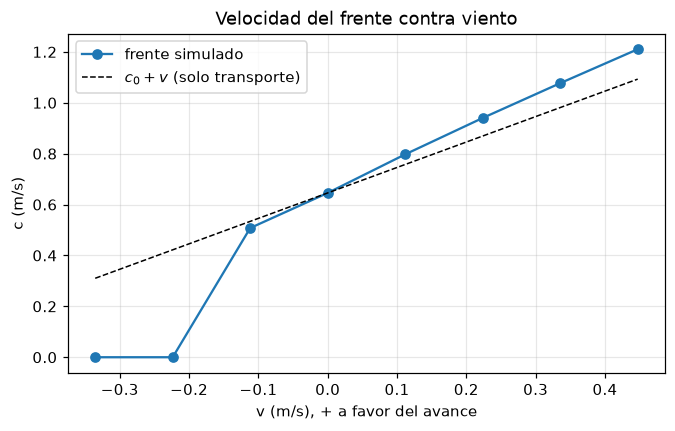

| w | v (m/s) | c (m/s) |
|---|---|---|
| -1.5 | -0.335 | 0.000 |
| -1.0 | -0.224 | 0.000 |
| -0.5 | -0.112 | 0.508 |
| +0.0 | +0.000 | 0.646 |
| +0.5 | +0.112 | 0.797 |
| +1.0 | +0.224 | 0.940 |
| +1.5 | +0.335 | 1.077 |
| +2.0 | +0.447 | 1.210 |

In [8]:
ws = np.array([-1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0])
c_w = np.array([front_speed(solve_1d(d, dx=0.2, w=w, length=120.0)) for w in ws])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ws * v0, c_w * v0, "o-", label="frente simulado")
ax.plot(ws * v0, (c_base + ws) * v0, "k--", lw=1, label=r"$c_0 + v$ (solo transporte)")
ax.set(xlabel="v (m/s), + a favor del avance", ylabel="c (m/s)", title="Velocidad del frente contra viento")
ax.legend()
plt.show()
display(Markdown("| w | v (m/s) | c (m/s) |\n|---|---|---|\n" + "\n".join(
    f"| {w:+.1f} | {w * v0:+.3f} | {c * v0:.3f} |" for w, c in zip(ws, c_w))))

El viento a favor acelera el frente y el viento en contra lo frena, hasta apagarlo si es suficientemente fuerte. La curva no es simplemente $c_0 + v$, porque el viento también cambia cuánto se precalienta el combustible de adelante. Con el upwind, el paso de tiempo adicional por CFL apenas importa a estas velocidades: la difusión sigue siendo la restricción dominante.

## Predicción teórica para validar el solver 2D

Por análisis dimensional, la velocidad del frente plano en terreno llano y sin viento es

$$c = c^*(a, b, e, \beta_0)\,\sqrt{\kappa C}$$

De aquí salen dos pruebas para el solver 2D:

1. Con los parámetros por defecto, un frente plano (ignición en una franja) debe avanzar a la velocidad de la tabla de arriba.
2. Si se cambia $\kappa$ manteniendo $a, b, e$, la velocidad debe escalar como $\sqrt{\kappa}$. Si se cambia $C$ manteniendo $a, b, e$ (es decir, ajustando también $A$ y $\varepsilon$), debe escalar como $\sqrt{C}$.

Guardamos la referencia en `analysis/results/frente_1d.json`.

In [9]:
out_dir = Path("results")
out_dir.mkdir(exist_ok=True)
reference = {
    "params": vars(p),
    "dimensionless": vars(d),
    "dx_xi": 0.2,
    "c_star": c_base,
    "c_star_converged": c_ref,
    "front_speed_m_s": c_base * v0,
    "front_speed_m_s_converged": c_ref * v0,
    "peak_T_K": peak_K,
    "residual_beta": residual,
    "propagation_beta0": beta_prop,
    "mesh": [{"dx_xi": dx, "dx_m": dx * L, "c_star": c} for dx, c, _, _ in conv],
    "wind": [{"w": float(w), "v_m_s": float(w * v0), "c_m_s": float(c * v0)} for w, c in zip(ws, c_w)],
}
(out_dir / "frente_1d.json").write_text(json.dumps(reference, indent=2))
print(json.dumps({k: reference[k] for k in ("c_star", "front_speed_m_s", "front_speed_m_s_converged", "peak_T_K", "residual_beta", "propagation_beta0")}, indent=2))

{
  "c_star": 2.88761811759789,
  "front_speed_m_s": 0.6456910404008863,
  "front_speed_m_s_converged": 0.6566302605659252,
  "peak_T_K": 1381.7432561843389,
  "residual_beta": 0.001643295754368382,
  "propagation_beta0": 0.7
}
